In [21]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

# 1. Business Understanding


In [22]:
import time
import keras
from keras import layers

import numpy as np
import matplotlib.pyplot as plt

TARGET_REALISTIC = (0.70, 0.75)
TARGET_AMBITIOUS = (0.78, 0.80)

### random seed for repeatability
RANDOM_SEED = 123
keras.utils.set_random_seed(RANDOM_SEED)

# 2. Data Understanding

In [23]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten()

class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

print("Train: ", x_train.shape, "Test: ", x_test.shape)
print("Pixel range: ", x_train.min(), "-", x_train.max())

Train:  (50000, 32, 32, 3) Test:  (10000, 32, 32, 3)
Pixel range:  0 - 255


### Sample Images

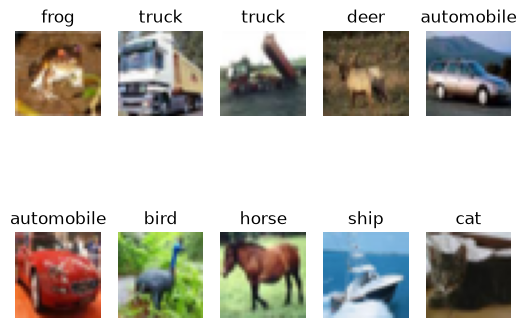

In [24]:
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(32, 32, 3))
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.show()

# 3. Data Preparation

In [25]:
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

# 4. Modeling

In [26]:
inputs = keras.Input(shape=(32, 32, 3))
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(inputs)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation="softmax")(x)
model = keras.Model(inputs=inputs, outputs=outputs)

In [27]:
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 30, 30, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 13, 13, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 4, 4, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 373,386 (1.42 MB)

 Trainable params: 373,386 (1.42 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)

In [29]:
t0 = time.time()
history = model.fit(
    x_train, y_train,
    batch_size=64,
    epochs=20,
    validation_split=0.2,
)
training_time = time.time() - t0
print("Training time: ", round(training_time, 1), " seconds")

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 33s 50ms/step - accuracy: 0.3643 - loss: 1.7018 - val_accuracy: 0.4688 - val_loss: 1.4666
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 23s 36ms/step - accuracy: 0.5101 - loss: 1.3649 - val_accuracy: 0.5497 - val_loss: 1.2657
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 23s 37ms/step - accuracy: 0.5688 - loss: 1.2210 - val_accuracy: 0.5959 - val_loss: 1.1622
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 23s 37ms/step - accuracy: 0.6058 - loss: 1.1203 - val_accuracy: 0.6208 - val_loss: 1.0876
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 23s 37ms/step - accuracy: 0.6364 - loss: 1.0394 - val_accuracy: 0.6385 - val_loss: 1.0325
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 36ms/step - accuracy: 0.6615 - loss: 0.9721 - val_accuracy: 0.6527 - val_loss: 0.9887
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.6813 - loss: 0.9136 - val_accuracy: 0.6695 - val_loss: 0.9445
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.7021 - loss: 0.8621 - 

# 5. Evaluation

## Learning curves

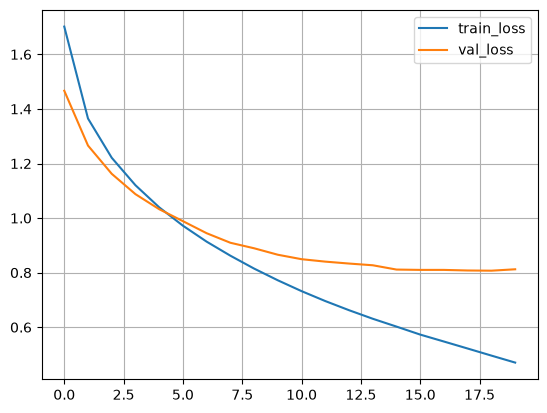

In [30]:
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.legend()
plt.grid()
plt.show()

## Test accuracy

In [31]:
test_scores = model.evaluate(x_test, y_test, verbose=2)

print("Test loss: ", test_scores[0])
print("Test accuracy: ", test_scores[1])

313/313 - 1s - 3ms/step - accuracy: 0.7338 - loss: 0.8385
Test loss:  0.8385445475578308
Test accuracy:  0.7337999939918518


## Probability distributions

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


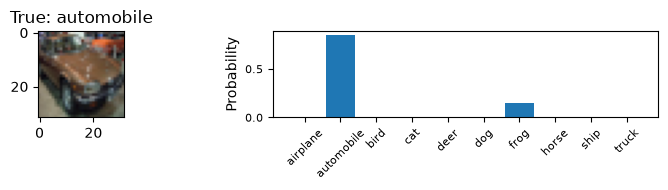

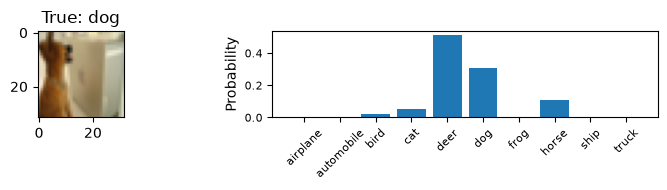

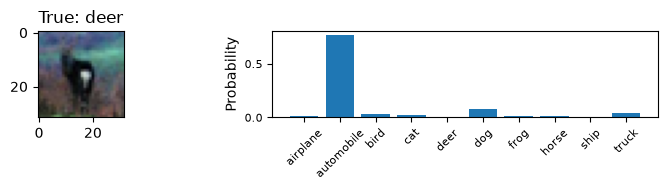

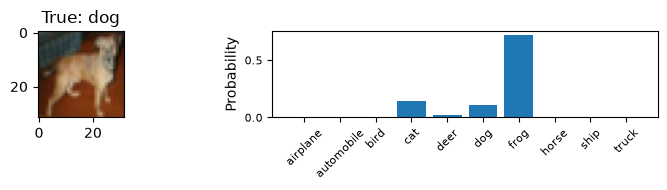

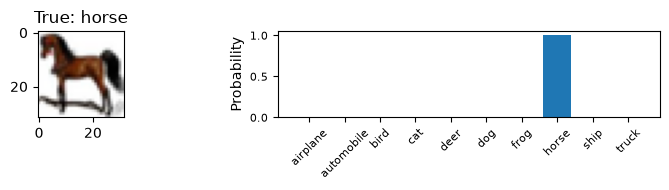

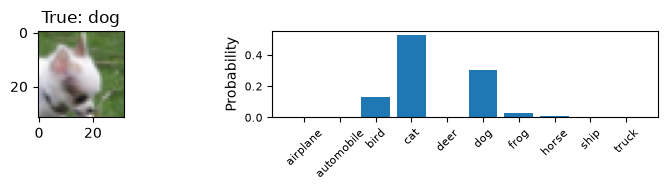

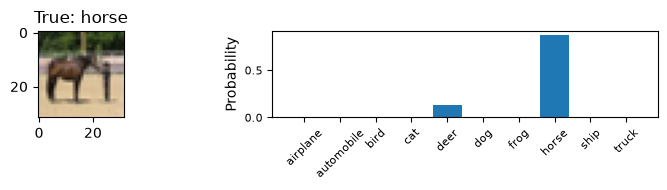

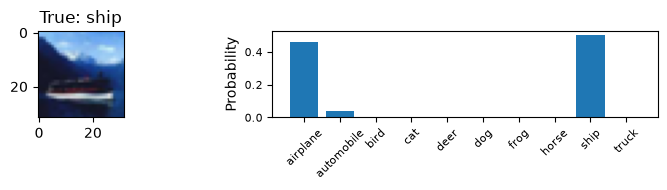

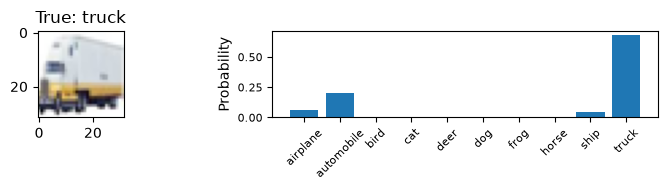

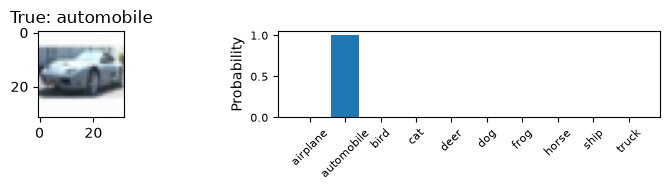

In [33]:
def to_img(x):
    img = x * 255
    return np.clip(img / 255, 0, 1)

y = model.predict(x_test)
start = 2000

for k in range(10):
    plt.figure(figsize=(8, 2))
    plt.subplot(1, 2, 1)
    plt.imshow(to_img(x_test[start + k]))
    plt.title("True: " + class_names[y_test[start+k]], fontsize=12)
    plt.subplot(1, 2, 2)
    plt.bar(np.arange(10), y[start+k])
    plt.xticks(range(10), class_names, rotation=45, fontsize=8)
    plt.yticks(fontsize=8)
    plt.ylabel("Probability", fontsize=10)
    plt.tight_layout()

## Misclassified images

Misclassified:  2662 / 10000


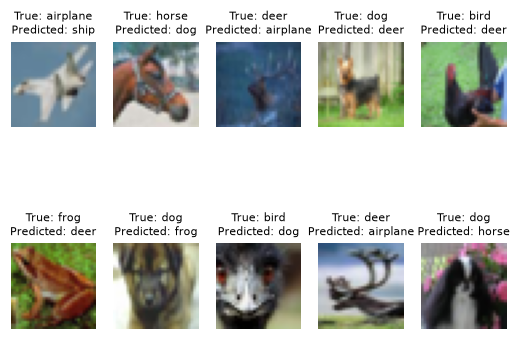

In [34]:
y_pred = np.argmax(y, axis=1)
wrong = np.where(y_pred != y_test)[0]

print("Misclassified: ", len(wrong), "/", len(y_test))

for k in range(10):
    i = wrong[k]
    plt.subplot(2, 5, k+1)
    plt.imshow(to_img(x_test[i]))
    plt.title(f"True: {class_names[y_test[i]]}\nPredicted: {class_names[y_pred[i]]}", fontsize=8)
    plt.axis("off")
plt.show()

## Comparison with FCN

In [35]:
FCN_TEST_ACCURACY = 0.4806
FCN_TRAINING_TIME = 79.3

print("FCN test accuracy: ", FCN_TEST_ACCURACY, " training time: ", FCN_TRAINING_TIME, " seconds")
print("CNN test accuracy: ", round(test_scores[1], 4), " training time: ", round(training_time, 1), " seconds")

FCN test accuracy:  0.4806  training time:  79.3  seconds
CNN test accuracy:  0.7338  training time:  424.1  seconds
